**LIBRARIES IMPORT**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**DATASET READ USING PANDAS**

In [2]:
df= pd.read_csv("Student_Depression_Dataset.csv")


**DATA UNDERSTANDING**

In [3]:
print("Shape of the data: ",df.shape)

Shape of the data:  (4464, 13)


In [4]:
print("Column names: ",df.columns)

Column names:  Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Semester', 'CGPA', 'friend_circle',
       'Health_condition', 'Cost_without_study', 'Home_division',
       'Depression'],
      dtype='str')


*FIRST 5 ROWS*

In [5]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


*INFO*

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Semester             4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


*NULL VALUE & DUPLICATE VALUE COUNT*

In [7]:
df.isnull().sum()
# NO NULL VALUES IN ANY COLUMN

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Semester               0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [8]:
print("DUPLICATED VALUES: ",df.duplicated().sum())
# NO DUPLICATE VALUES

DUPLICATED VALUES:  0


*CORRELATION BETWEEN NUMERIC COLUMNS*

In [9]:
df.corr(numeric_only=True)

,Age,Semester,CGPA,Cost_without_study
Age,1.000000,0.325304,-0.065085,-0.062625
Semester,0.325304,1.000000,-0.007946,0.013762
CGPA,-0.065085,-0.007946,1.000000,0.081900
Cost_without_study,-0.062625,0.013762,0.081900,1.000000


*DESCRIPTION OF NUMERICAL DATA*

In [10]:
df.describe().round(3)

,Age,Semester,CGPA,Cost_without_study
count,4464.000,4464.000,4464.000,4464.000
mean,22.619,5.401,3.413,11242.978
std,2.023,2.578,0.386,6640.144
min,17.000,0.000,2.250,0.000
25%,21.000,3.000,3.150,6100.000
50%,23.000,5.000,3.490,9500.000
75%,24.000,7.000,3.700,15439.000
max,28.000,13.000,4.000,32000.000


**EXPLORATORY DATA ANALYSIS: USING GRAPHS**

In [11]:
# style change
sns.set_style("darkgrid")

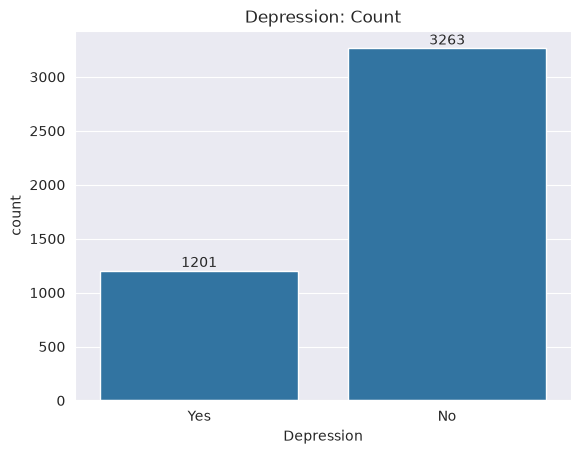

In [12]:
# 1: Count vs Depression
count= sns.countplot(data=df,x=df["Depression"])
plt.title("Depression: Count")

for container in count.containers:
    count.bar_label(container, fmt='%d', padding=0.5)
    
plt.savefig("outputs/Depression-count.png")

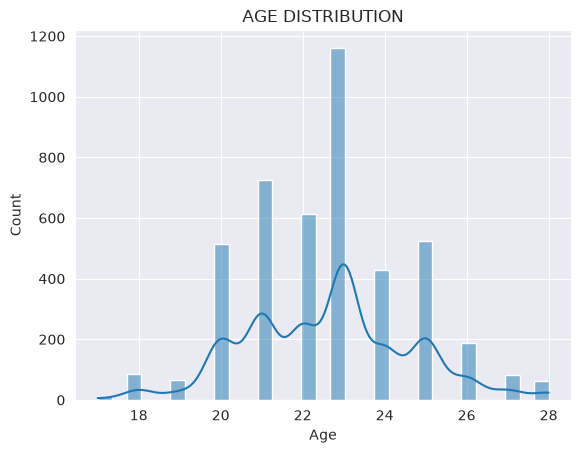

In [13]:
#2: Age Distribution
h= sns.histplot(x=df["Age"],data=df,kde=True) 
plt.title("AGE DISTRIBUTION")

plt.savefig("outputs/Age-distribution.png")

*The above Graph shows that data is of students: mostly from age group 20-26 years*

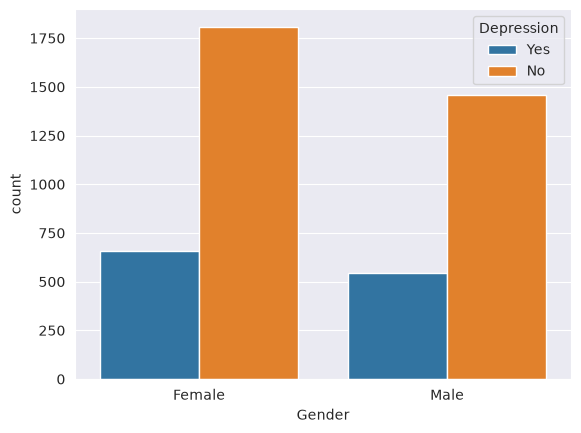

In [14]:
# 3. Depression count with gender %age:
gender= sns.countplot(x=df["Gender"],data=df,hue=df["Depression"])
plt.savefig("outputs/genderVsDepressoin.png")

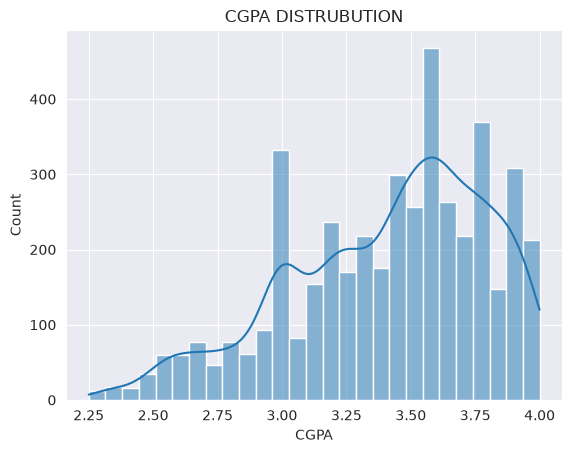

In [15]:
# 4: CGPA Distribution
cgpa= sns.histplot(data= df,x=df["CGPA"],kde=True)
plt.title("CGPA DISTRUBUTION")
plt.savefig("outputs/CGPA-count.png")

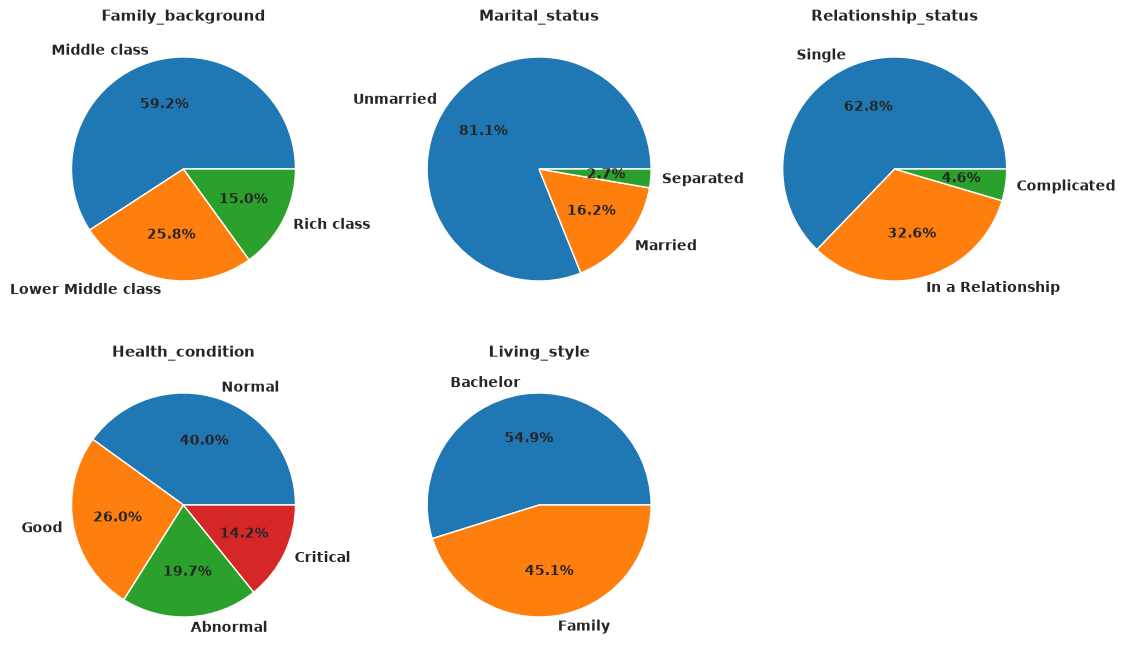

In [16]:
# 5:  Pie charts of different columns showing %ages
columns = ['Family_background', 'Marital_status', 'Relationship_status', 'Health_condition', 'Living_style']
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()  # Converts 2D array into 1D array

for ax, col in zip(axes, columns):
    counts = df[col].value_counts()

    ax.pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        textprops={'fontweight': 'bold'}
    )

    ax.set_title(col, fontsize=11, fontweight='bold')
axes[5].axis('off')  # Hide the sixth empty subplot

plt.savefig("outputs/Column-pieCharts.png")

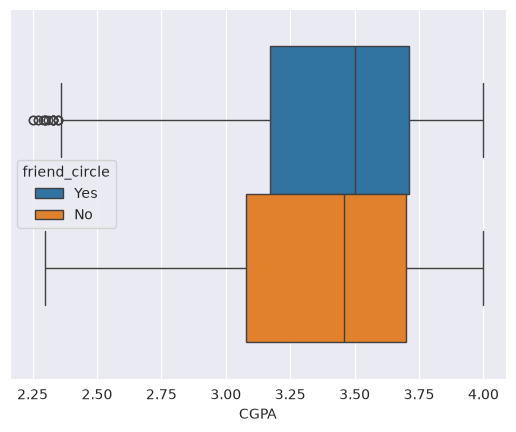

In [17]:
# 6. CGPA analysis using Living_style
sns.boxplot(x=df["CGPA"],data=df,hue=df["friend_circle"])
plt.savefig("outputs/FriendCircleVSCGPA.png")